# Лабораторная работа № 2.4
---
«Выявление скрытых переменных на основе метода PCA»

Рязанцев Георгий Борисович

## 1. Импорт библиотек, загрузка данных и стандартизация

In [ ]:
#импортируем необходимые библиотеки
import pandas as pd
import seaborn as sns
from sklearn import preprocessing
from sklearn.decomposition import PCA
import pylab as plt


#загрузим данные
data = pd.read_csv('Rural_prices.csv', sep=";", decimal=",")

#выберем переменные для модели
x1 = data.drop('sale price', axis=1)
y1 = data['sale price']

In [ ]:
# Дополнительно (в методичке отсутствует): сохраняем исходную таблицу признаков и их названия,
# потому что стандартизация ниже заменяет x1 массивом NumPy без названий столбцов
x1_raw = x1.copy()
feature_names = x1.columns.tolist()

print('Данные:', data.shape, '| признаки x1:', x1.shape, '| целевая y1:', y1.shape)
print('Признаки:', feature_names)
print('Пропусков:', int(data.isna().sum().sum()))

Данные: (546, 12) | признаки x1: (546, 11) | целевая y1: (546,)
Признаки: ['lot size', '#bedroom', '#bath', '#stories', 'driveway', 'rec room', 'basement', 'gas', 'air cond', '#garage', 'desire loc']
Пропусков: 0


In [ ]:
# Стандартизация данных
x1 = preprocessing.StandardScaler().fit(x1).transform(x1)

In [ ]:
# Дополнительно: проверка стандартизации (формула 2.4: z = (x - среднее) / стандартное отклонение)
print('Тип x1 после стандартизации:', type(x1).__name__, x1.shape)
print('Максимальное |среднее| по столбцам:', abs(x1.mean(axis=0)).max().round(12))
print('Стандартные отклонения столбцов:', x1.std(axis=0).round(6).tolist())

Тип x1 после стандартизации: ndarray (546, 11)
Максимальное |среднее| по столбцам: 0.0
Стандартные отклонения столбцов: [1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0]


**Сверка с рис. 2.31.** Код совпадает с методичкой; данные те же, что в работах 2.3 и 2.6: 546 наблюдений, 11 признаков, целевая `sale price`, пропусков нет. Стандартизация по формуле (2.4): средние 0, отклонения 1 (проверка выше). PCA строится только по признакам — `sale price` в нём не участвует.

**Почему добавлена ячейка с `x1_raw`.** Строка методички `x1 = ...transform(x1)` заменяет таблицу массивом NumPy, названия столбцов теряются; они нужны для таблицы компонент (раздел 3), поэтому исходная таблица сохранена отдельно. `seaborn` импортируется по методичке, но не используется.

## 2. Анализ главных компонент и график каменистой осыпи

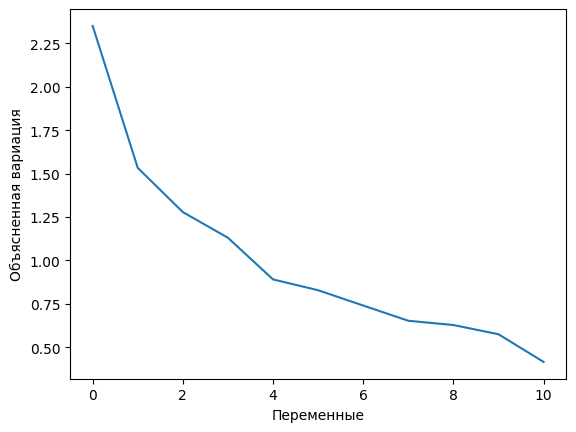

In [ ]:
# Создание экземпляра класса анализа главных компонент
model = PCA()

# Применение PCA к свободным переменным для поиска возможности свертки их в меньшее количество переменных
# Результат преобразуется в массив для использования вновь созданных данных
results = model.fit(x1)
Z = results.transform(x1)

# График объясняемой дисперсии переменных: в данном случае график каменистой осыпи
plt.plot(results.explained_variance_)
plt.xlabel('Переменные')
plt.ylabel('Объясненная вариация')
# Отображение графика
plt.show()

In [ ]:
# Дополнительно: доли объяснённой дисперсии (график выше показывает собственные значения, а не проценты)
import numpy as np

pca_table = pd.DataFrame({
    'Собственное значение': results.explained_variance_,
    'Доля, %': results.explained_variance_ratio_ * 100,
    'Накопленная доля, %': results.explained_variance_ratio_.cumsum() * 100,
}, index=['PC%d' % i for i in range(1, len(results.explained_variance_) + 1)])
print(pca_table.round(2).to_string())
print()
print('Сумма собственных значений:', results.explained_variance_.sum().round(3), '(число признаков:', x1.shape[1], ')')
print('Компоненты с собственным значением > 1 (критерий Кайзера):', int((results.explained_variance_ > 1).sum()))

# Проверка соответствия описанию в методичке (ковариационная матрица -> собственные значения)
eig = np.sort(np.linalg.eigvalsh(np.cov(x1.T)))[::-1]
print('Собственные значения ковариационной матрицы совпадают с explained_variance_:', np.allclose(eig, results.explained_variance_))
print('Форма Z (новые координаты):', Z.shape)

      Собственное значение  Доля, %  Накопленная доля, %
PC1                   2.35    21.33                21.33
PC2                   1.53    13.91                35.24
PC3                   1.28    11.60                46.84
PC4                   1.13    10.26                57.09
PC5                   0.89     8.08                65.17
PC6                   0.83     7.51                72.69
PC7                   0.74     6.71                79.40
PC8                   0.65     5.92                85.32
PC9                   0.63     5.70                91.02
PC10                  0.57     5.21                96.23
PC11                  0.42     3.77               100.00

Сумма собственных значений: 11.02 (число признаков: 11 )
Компоненты с собственным значением > 1 (критерий Кайзера): 4
Собственные значения ковариационной матрицы совпадают с explained_variance_: True
Форма Z (новые координаты): (546, 11)


**Сверка с рис. 2.32–2.33.** Код совпадает с рис. 2.32; расхождения только в подписях: у осей графика добавлены `xlabel`/`ylabel` (на рис. 2.33 они есть, в коде рис. 2.32 — нет); по оси x компоненты нумеруются с нуля.

**Что показано на графике.** `explained_variance_` — собственные значения ковариационной матрицы (сумма 11,02 ≈ число признаков), а не проценты; доли в процентах — в таблице выше (`explained_variance_ratio_`). Совпадение с `np.linalg.eigvalsh(np.cov(...))` подтверждает описание шагов PCA из теории методички.

**Расхождение текста методички с её рисунком.** Текст называет доли 25 %, 16 %, 13 %…; фактический запуск даёт 21,33 %, 13,91 %, 11,60 %… — наши значения совпадают с ординатами рис. 2.33 (≈2,35; ≈1,53; …), проценты из текста завышены. Верными считать значения из таблицы.

**Сколько компонент достаточно.** Первые 4 объясняют 57,1 % дисперсии, первые 5 — 65,2 %, первые 8 — 85,3 %; по критерию Кайзера значимых компонент 4. Утверждение методички «первые 5 переменных содержат большую часть информации» верно лишь частично (около двух третей).

## 3. Компоненты PCA во фрейме данных

In [ ]:
pd.DataFrame(results.components_, columns=list(
    ['lot size',
     '#bedroom',
     '#bath',
     '#stories',
     'driveway',
     'rec room',
     'basement',
     'gas',
     'air cond',
     '#garage',
     'desire loc']))

,lot size,#bedroom,#bath,#stories,driveway,rec room,basement,gas,air cond,#garage,desire loc
0,0.392165,0.366846,0.385501,0.332323,0.260635,0.251864,0.174452,0.000677,0.346017,0.314548,0.268537
1,0.159181,-0.330685,-0.251365,-0.486772,0.209912,0.364192,0.489260,-0.094980,-0.093307,0.072276,0.355179
2,-0.368968,0.293716,0.237495,0.057411,-0.442992,0.401912,0.466119,0.076738,-0.054656,-0.365077,-0.026347
3,0.100700,0.087177,0.164832,-0.183413,-0.004691,-0.054802,0.091838,0.770142,-0.422068,0.344630,-0.141282
4,0.164573,-0.010785,0.123793,-0.346933,-0.477762,-0.008236,0.106873,-0.316418,0.237737,0.488430,-0.449626
5,0.075060,0.333313,0.122560,-0.150674,-0.265440,-0.490378,0.058812,-0.290586,-0.382084,0.062463,0.544818
6,0.027216,-0.140571,-0.249961,-0.014633,-0.457046,-0.143170,-0.054817,0.440591,0.561857,-0.000186,0.417860
7,0.610147,-0.130284,0.150181,-0.038860,-0.320642,0.373207,-0.418914,-0.003133,-0.235757,-0.333577,0.047267
8,-0.082560,-0.496711,0.745150,-0.169993,0.109703,-0.264665,0.076910,0.033083,0.163073,-0.206478,0.063227
9,-0.439705,-0.309442,0.140059,0.224517,-0.162354,0.355909,-0.316631,-0.100430,-0.205550,0.494318,0.301509


In [ ]:
# Дополнительно: те же компоненты с подписями строк и проверка, что список названий в коде совпадает с таблицей данных
loadings = pd.DataFrame(results.components_, columns=feature_names, index=['PC%d' % i for i in range(1, 12)])
print('Список названий в ячейке выше совпадает с feature_names:',
      list(['lot size', '#bedroom', '#bath', '#stories', 'driveway', 'rec room', 'basement', 'gas', 'air cond', '#garage', 'desire loc']) == feature_names)
print()
# признаки с наибольшими по модулю весами в первых четырёх компонентах
for pc in ['PC1', 'PC2', 'PC3', 'PC4']:
    top = loadings.loc[pc].abs().sort_values(ascending=False).head(3).index
    print(pc, ':', ', '.join('%s (%.2f)' % (f, loadings.loc[pc, f]) for f in top))

Список названий в ячейке выше совпадает с feature_names: True

PC1 : lot size (0.39), #bath (0.39), #bedroom (0.37)
PC2 : basement (0.49), #stories (-0.49), rec room (0.36)
PC3 : basement (0.47), driveway (-0.44), rec room (0.40)
PC4 : gas (0.77), air cond (-0.42), #garage (0.34)


**Сверка.** Код совпадает с методичкой (рис. на стр. 47): строки — главные компоненты, столбцы — признаки, значения — нагрузки. Названия столбцов в методичке заданы списком вручную; дополнительная ячейка проверяет, что его порядок совпадает с порядком столбцов `x1` (несовпадение подписало бы компоненты неверно). Знак компоненты смысла не несёт — значимы относительные величины весов.

**Интерпретация нагрузок (доли дисперсии — из таблицы раздела 2).**
- **PC1 (21,3 %)** — все веса положительны: `lot size` (0,39), `#bath` (0,39), `#bedroom` (0,37), `#stories` (0,33). Общий фактор «размер и благоустроенность дома».
- **PC2 (13,9 %)** — противопоставление `#stories` (−0,49), `#bedroom` (−0,33) признакам `basement` (0,49), `rec room` (0,36), `desire loc` (0,36).
- **PC3 (11,6 %)** — `basement` (0,47), `rec room` (0,40) против `driveway` (−0,44), `lot size` (−0,37).
- **PC4 (10,3 %)** — почти целиком `gas` (0,77): редкий признак (газ ≈ у 5 % домов), а не общий фактор.

Названия компонент — содержательная трактовка весов, не строгий вывод.

## 4. Прогноз до применения PCA (наивный байесовский классификатор)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import confusion_matrix
import pylab as plt
# Выбор наивного классификатора Байеса; для оценки вероятности применяется гауссово распределение
gnb = GaussianNB()
# Подгонка данных
fit = gnb.fit(x1, y1)
# Прогнозирование для неизвестных данных
pred = fit.predict(x1)
# Изучение матрицы несоответствий
print(confusion_matrix(pred,y1))
# Подсчет правильно классифицированных случаев
print(confusion_matrix(pred,y1).trace())

[[0 0 0 ... 0 0 0]
 [0 1 0 ... 0 0 0]
 [0 0 1 ... 0 0 0]
 ...
 [0 0 0 ... 1 0 0]
 [0 0 0 ... 0 1 0]
 [0 0 0 ... 0 0 1]]


196


In [ ]:
# Дополнительно: что на самом деле классифицирует модель
n_classes = y1.nunique()
correct_raw = int(confusion_matrix(pred, y1).trace())
print('Число различных значений sale price (число «классов»):', n_classes)
print('Классов, встречающихся в данных ровно один раз:', int((y1.value_counts() == 1).sum()))
print('Размер матрицы несоответствий:', confusion_matrix(pred, y1).shape)
print()
print('Правильных прогнозов: %d из %d (%.1f %%)' % (correct_raw, len(y1), 100 * correct_raw / len(y1)))
print('Для сравнения: прогноз самой частой цены (%s) дал бы %.1f %%' % (y1.mode()[0], 100 * y1.value_counts().max() / len(y1)))

Число различных значений sale price (число «классов»): 219
Классов, встречающихся в данных ровно один раз: 108
Размер матрицы несоответствий: (219, 219)

Правильных прогнозов: 196 из 546 (35.9 %)
Для сравнения: прогноз самой частой цены (50000) дал бы 3.1 %


**Сверка с рис. 2.34–2.35.** Код соответствует методичке. Методичка: 196 верных прогнозов из 546 (35,9 %); наш запуск даёт те же 196 (35,9 %) — расхождений нет.

Как читать результат (три особенности методики методички):
1. **Цена как «класс».** `GaussianNB` предсказывает точное значение цены как категорию (219 «классов», 108 из них встречаются один раз); матрица несоответствий 219×219 выводится сокращённо, как на рис. 2.35. Ориентир: «всегда самая частая цена» дала бы 3,1 %.
2. **Оценка на обучающей выборке.** Разбиения нет, модель частично запоминает объекты — 35,9 % завышены относительно качества на новых данных (проверка в разделе 6).
3. **Порядок аргументов `confusion_matrix(pred, y1)`** обратный соглашению sklearn: матрица транспонирована, но след (число верных) не меняется — на результат не влияет.

## 5. Прогноз с наращиванием количества главных компонент

[156]
[156, 170]
[156, 170, 183]
[156, 170, 183, 217]
[156, 170, 183, 217, 236]
[156, 170, 183, 217, 236, 254]


[156, 170, 183, 217, 236, 254, 250]


[156, 170, 183, 217, 236, 254, 250, 271]


[156, 170, 183, 217, 236, 254, 250, 271, 289]


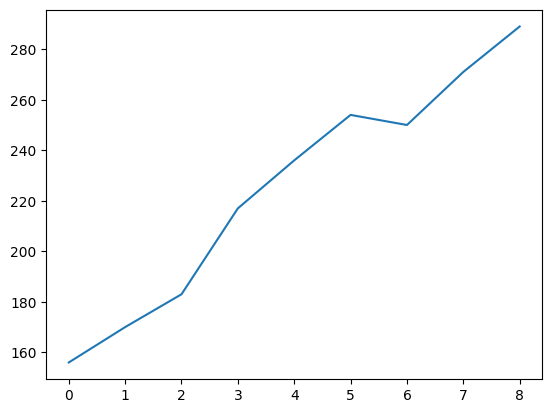

In [ ]:
# Массив будет заполнен правильно спрогнозированными наблюдениями
predicted_correct = []
for i in range(1,10): # Перебор первых 10 обнаруженных главных компонент
    model = PCA(n_components = i) # Создание экземпляра модели PCA с разным количеством компонентов
    results = model.fit(x1) # Подгонка модели PCA по х=переменным
    Z = results.transform(x1) # Z содержит результат в форме матрицы
    fit = gnb.fit(Z,y1) # Применение наивного классификатора Байеса с гауссовым распределением для оценки
    pred = fit.predict(Z) # Собственно прогнозирование с использованием подогнанной модели
    # В конце каждой итерации добавляется новое количество правильно классифицированных наблюдений
    predicted_correct.append(int(confusion_matrix(pred,y1).trace()))
    print(predicted_correct) # Выводя этот массив, видно добавление новых наблюдений
plt.plot(predicted_correct) # Результат в графической форме
plt.show() # Вывод графика

[156, 170, 183, 217, 236, 254, 250, 271, 289, 298, 307]


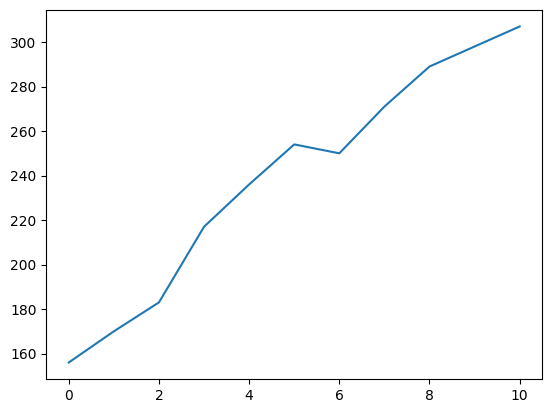

In [ ]:
# То же для всех 11 компонент (рис. 2.38): диапазон расширен до range(1, 12)
predicted_correct = []
for i in range(1,12):
    model = PCA(n_components = i)
    results = model.fit(x1)
    Z = results.transform(x1)
    fit = gnb.fit(Z,y1)
    pred = fit.predict(Z)
    predicted_correct.append(int(confusion_matrix(pred,y1).trace()))
print(predicted_correct)
plt.plot(predicted_correct)
plt.show()

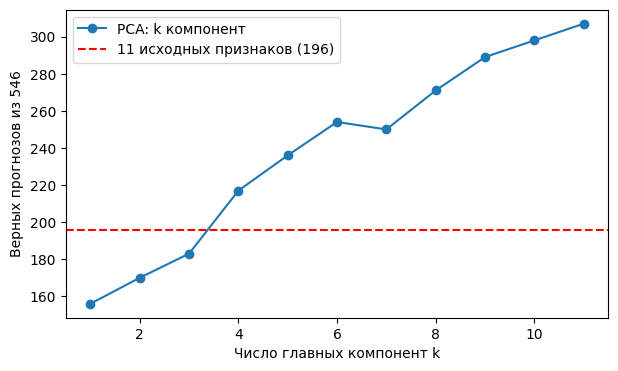

Первое k, при котором результат выше, чем на исходных признаках: 4
Доля верных прогнозов при k = 11: 56.2 %


In [ ]:
# Дополнительно: тот же график с правильной осью (число компонент) и ориентиром — результатом на исходных признаках
plt.figure(figsize=(7, 4))
plt.plot(range(1, 12), predicted_correct, marker='o', label='PCA: k компонент')
plt.axhline(correct_raw, color='red', linestyle='--', label='11 исходных признаков (%d)' % correct_raw)
plt.xlabel('Число главных компонент k')
plt.ylabel('Верных прогнозов из %d' % len(y1))
plt.legend()
plt.show()

better = [k for k, c in zip(range(1, 12), predicted_correct) if c > correct_raw]
print('Первое k, при котором результат выше, чем на исходных признаках:', better[0] if better else 'нет')
print('Доля верных прогнозов при k = 11: %.1f %%' % (100 * predicted_correct[-1] / len(y1)))

**Сверка с рис. 2.36–2.38.** Циклы выполнены как в методичке: первый — `range(1, 10)` (фактически 1–9 компонент, несмотря на комментарий «первых 10»; рис. 2.37 подписан «9 скрытых переменных»), второй расширен до `range(1, 12)` ради 11 компонент (рис. 2.38). Ось x на графиках методички сдвинута: индекс 0 = одна компонента; дополнительный график строит ту же кривую при k = 1…11 с ориентиром по исходным признакам. `int(...)` вокруг `.trace()` — только формат вывода (иначе numpy печатает `np.int64(...)`). Все числа — точные совпадения цены на обучающей выборке (раздел 4).

**Результат.** Массив для 1–11 компонент `[156, 170, 183, 217, 236, 254, 250, 271, 289, 298, 307]` совпадает с рис. 2.37–2.38.
- Порог исходных признаков (196) превышается с **k = 4** (217 > 196), как пишет методичка.
- Провал приходится на k = 7 (250 после 254 при k = 6).
- При k = 11 — 307 из 546 (56,2 %); в методичке «более 300, то есть 55 %» — совпадает.
- Прирост на последних компонентах меньше, чем на первых (k = 9→11: +18 против +34 на k = 3→4), как в методичке.

**Почему растёт «прогностическая сила».** При k = 11 PCA — это поворот осей без потери информации: «новой информации» не появляется. Рост обусловлен тем, что некоррелированные компоненты лучше соответствуют предположению `GaussianNB` о независимости признаков, плюс подгонка на обучающей выборке (см. раздел 6).

## 6. Проверка на отложенной выборке (дополнительно)

Вывод методички о сильном росте прогностической способности получен на обучающих данных и для точного совпадения цены. Здесь то же сравнение выполняется на тестовой выборке (80/20, 10 разбиений; seed = номер разбиения 0–9). Стандартизация и PCA подгоняются только по обучающей части (`Pipeline`), чтобы тестовые данные не просачивались в модель. Дополнительно считается более осмысленная метрика — доля прогнозов с ошибкой не более 10 %.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

def holdout_scores(make_model, n_splits=10):
    exact, within10 = [], []
    for seed in range(n_splits):
        Xtr, Xte, ytr, yte = train_test_split(x1_raw, y1, test_size=0.2, random_state=seed)
        m = make_model().fit(Xtr, ytr)
        p = m.predict(Xte)
        exact.append((p == yte).mean())
        within10.append((abs(p - yte) / yte <= 0.10).mean())
    return np.mean(exact), np.mean(within10)

rows = {'Исходные 11 признаков': holdout_scores(lambda: make_pipeline(StandardScaler(), GaussianNB()))}
for k in range(1, 12):
    rows['PCA, k = %d' % k] = holdout_scores(lambda k=k: make_pipeline(StandardScaler(), PCA(n_components=k), GaussianNB()))

hold = pd.DataFrame(rows, index=['Точное совпадение цены, %', 'Ошибка не более 10 %, %']).T * 100
print(hold.round(1).to_string())
print()
print('Для сравнения, обучающая выборка (как в методичке), k = 11: %.1f %% точных совпадений' % (100 * predicted_correct[-1] / len(y1)))

                       Точное совпадение цены, %  Ошибка не более 10 %, %
Исходные 11 признаков                        0.6                     26.9
PCA, k = 1                                   1.5                     30.0
PCA, k = 2                                   1.8                     31.0
PCA, k = 3                                   1.2                     31.7
PCA, k = 4                                   1.2                     30.7
PCA, k = 5                                   1.5                     31.9
PCA, k = 6                                   1.4                     31.0
PCA, k = 7                                   1.3                     31.6
PCA, k = 8                                   1.5                     31.5
PCA, k = 9                                   1.8                     31.7
PCA, k = 10                                  1.9                     31.1
PCA, k = 11                                  1.5                     32.1

Для сравнения, обучающая выборка (как

**Результат (таблица выше — среднее по 10 разбиениям).**
- **Точное совпадение цены:** 0,6 % на исходных признаках и 1,2–1,9 % при любых k от 1 до 11 — против 35,9 % и 56,2 % на обучающей выборке. Точно угадать цену на новых объектах модель практически не может: «прогностическая сила» методички — преимущественно запоминание обучения.
- **Ошибка ≤ 10 %:** 26,9 % на исходных признаках против 30,0–32,1 % на компонентах — небольшое преимущество PCA (≈3–5 п.п.) сохраняется (некоррелированные компоненты лучше для `GaussianNB`), но оно мало.
- Зависимость от числа компонент слабая: от k = 1 (30,0 %) до k = 11 (32,1 %) прирост ~2 п.п. Вывод методички «добавление скрытых переменных сильно повышает прогностическую способность» на новых данных **не подтверждается**: рост 156 → 307 на обучении вызван подгонкой.

## 7. Регрессия на главных компонентах (дополнительно)

**Зачем.** Задание формулируется как «объяснить показатель `sale price` с использованием разных характеристик», то есть цена — числовая переменная, и естественный способ оценить пользу PCA — регрессия на главных компонентах: сколько компонент достаточно, чтобы объяснять цену не хуже, чем 11 исходных признаков. R² считается кросс-валидацией (5 блоков), PCA и стандартизация подгоняются внутри каждого блока.

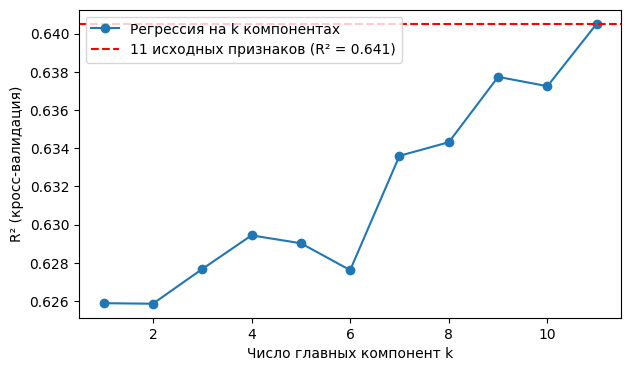

[0.626, 0.626, 0.628, 0.629, 0.629, 0.628, 0.634, 0.634, 0.638, 0.637, 0.641]
R² на 11 исходных признаках: 0.641
Минимальное k, при котором R² не хуже лучшего на 0.01: 7


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_val_score, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)
r2_pcr = []
for k in range(1, 12):
    pipe = make_pipeline(StandardScaler(), PCA(n_components=k), LinearRegression())
    r2_pcr.append(cross_val_score(pipe, x1_raw, y1, cv=cv, scoring='r2').mean())
r2_full = cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), x1_raw, y1, cv=cv, scoring='r2').mean()

plt.figure(figsize=(7, 4))
plt.plot(range(1, 12), r2_pcr, marker='o', label='Регрессия на k компонентах')
plt.axhline(r2_full, color='red', linestyle='--', label='11 исходных признаков (R² = %.3f)' % r2_full)
plt.xlabel('Число главных компонент k')
plt.ylabel('R² (кросс-валидация)')
plt.legend()
plt.show()

print([round(float(r), 3) for r in r2_pcr])
print('R² на 11 исходных признаках:', round(float(r2_full), 3))
print('Минимальное k, при котором R² не хуже лучшего на 0.01:',
      next(k for k, r in zip(range(1, 12), r2_pcr) if r >= max(r2_pcr) - 0.01))

**Результат.** R² кросс-валидации почти не зависит от числа компонент: 0,626 при k = 1–2, 0,629 при k = 4–5, 0,634 при k = 7–8, 0,641 при k = 11. Максимум при k = 11 совпадает с R² регрессии на исходных признаках (0,641) — ожидаемо: при k = 11 PCA лишь поворачивает оси. Разрыв k = 1 против k = 11 — 0,015: первая компонента объясняет почти всё, что доступно линейной модели; согласуется с работой 2.3 (линейные модели ≈ 0,65–0,67).

Причина: PC1 — фактор «размер дома» (раздел 3), её корреляция с ценой 0,80 (самостоятельная работа), откуда R² ≈ 0,80² ≈ 0,64. Здесь направление максимальной дисперсии случайно совпало с главным фактором цены; в общем случае так не бывает.

## Выводы по заданию

1. Данные стандартизированы (среднее 0, отклонение 1), PCA построен на 11 признаках. Первые 4 компоненты объясняют 57,1 % дисперсии, первые 5 — 65,2 %, первые 8 — 85,3 %; по критерию Кайзера значимых компонент 4.
2. Проценты из текста методички (25 %, 16 %, 13 %…) не соответствуют её рис. 2.33: фактические доли — 21,33 %, 13,91 %, 11,60 %…; утверждение «первые 5 переменных содержат большую часть информации» верно лишь частично (65 %).
3. PC1 — общий фактор «размер и благоустроенность дома»; её корреляция с ценой 0,80, PC2 с ценой почти не связана (−0,03).
4. Результат методики воспроизведён: 196 верных прогнозов из 546 (35,9 %) на исходных признаках, 307 (56,2 %) на 11 компонентах, превышение уровня исходных признаков — с 4 компонент.
5. Эти показатели получены на обучающей выборке при точном совпадении цены (219 «классов»). На отложенной выборке: 0,6 % (исходные) и 1,2–1,9 % (компоненты); с ошибкой ≤ 10 % — 27 % против 30–32 %. Рост «прогностической силы» — подгонка и следствие некоррелированности компонент для `GaussianNB`, а не новая информация.
6. Для числовой цены корректнее регрессия на компонентах: R² (CV) = 0,626 уже при одной компоненте и 0,641 при всех 11 (столько же, сколько на исходных признаках); разрыв между k = 1 и k = 11 — всего 0,015, то есть сжатие 11 признаков до одной компоненты почти не снижает качество линейного прогноза.
7. PCA не использует целевую переменную и не гарантирует, что компонента с большой дисперсией важна для цены. Метод стоит применять для сжатия данных и устранения мультиколлинеарности, а не как способ повысить качество прогноза.

## Самостоятельная работа

Требуется: используя `Rural_prices.csv`, построить метод PCA, вывести процент объяснённой вариации для 11 компонент и визуализировать результат для первых двух компонент. Используется набор библиотек, заданный в методичке.

In [ ]:
# Самостоятельная работа, шаг 1: библиотеки по методичке
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# В методичке самостоятельная работа начинается с исходной таблицы признаков x1;
# в ноутбуке x1 уже заменена стандартизованным массивом, поэтому возвращаем таблицу из x1_raw
x1 = x1_raw

In [ ]:
# Шаг 2: стандартизировать данные
scaler = StandardScaler()
X_scaled = scaler.fit_transform(x1)

In [ ]:
# Шаг 3: применить PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

In [ ]:
# Шаг 4: доли объяснённой дисперсии
explained_variance = pca.explained_variance_ratio_
print(f'Объясненная дисперсия первой главной компоненты: {explained_variance[0]:.2%}')
print(f'Объясненная дисперсия второй главной компоненты: {explained_variance[1]:.2%}')

Объясненная дисперсия первой главной компоненты: 21.33%
Объясненная дисперсия второй главной компоненты: 13.91%


In [ ]:
# Шаг 4 (продолжение): доли объяснённой дисперсии для всех 11 компонент, как требует задание
pca_full = PCA(n_components=11)
pca_full.fit(X_scaled)
ratio_full = pca_full.explained_variance_ratio_

for i, r in enumerate(ratio_full, start=1):
    print(f'Компонента {i:2d}: {r:7.2%}   накопленная доля: {ratio_full[:i].sum():7.2%}')
print('Сумма долей 11 компонент:', f'{ratio_full.sum():.2%}')
print('Первые две доли не зависят от запрошенного числа компонент (n_components=2 vs 11):',
      np.allclose(explained_variance, ratio_full[:2]))
print('Стандартизация здесь даёт тот же массив, что x1 в основной части:',
      np.allclose(X_scaled, preprocessing.StandardScaler().fit_transform(x1_raw)))

Компонента  1:  21.33%   накопленная доля:  21.33%
Компонента  2:  13.91%   накопленная доля:  35.24%
Компонента  3:  11.60%   накопленная доля:  46.84%
Компонента  4:  10.26%   накопленная доля:  57.09%
Компонента  5:   8.08%   накопленная доля:  65.17%
Компонента  6:   7.51%   накопленная доля:  72.69%
Компонента  7:   6.71%   накопленная доля:  79.40%
Компонента  8:   5.92%   накопленная доля:  85.32%
Компонента  9:   5.70%   накопленная доля:  91.02%
Компонента 10:   5.21%   накопленная доля:  96.23%
Компонента 11:   3.77%   накопленная доля: 100.00%
Сумма долей 11 компонент: 100.00%
Первые две доли не зависят от запрошенного числа компонент (n_components=2 vs 11): True
Стандартизация здесь даёт тот же массив, что x1 в основной части: True


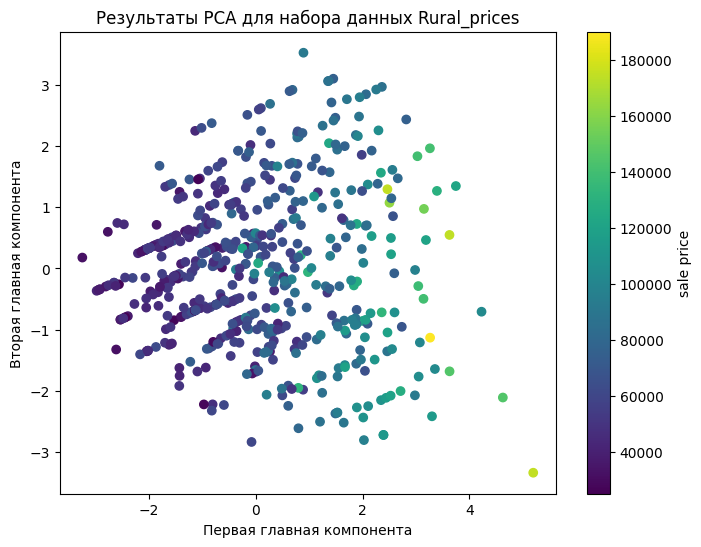

In [ ]:
# Шаг 5: визуализация результатов PCA для двух первых компонент
plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y1, cmap='viridis')
plt.colorbar().set_label('sale price')
plt.xlabel('Первая главная компонента')
plt.ylabel('Вторая главная компонента')
plt.title('Результаты PCA для набора данных Rural_prices')
plt.show()

In [ ]:
# Дополнительно: связь компонент с ценой
print('Корреляция PC1 с ценой: %.3f' % np.corrcoef(X_pca[:, 0], y1)[0, 1])
print('Корреляция PC2 с ценой: %.3f' % np.corrcoef(X_pca[:, 1], y1)[0, 1])
print('Доля дисперсии, объяснённая двумя компонентами вместе: %.2f %%' % (100 * explained_variance.sum()))

Корреляция PC1 с ценой: 0.799
Корреляция PC2 с ценой: -0.025
Доля дисперсии, объяснённая двумя компонентами вместе: 35.24 %


**Отличия от методички и обоснование.**
- **Противоречие в задании.** Условие требует доли для 11 компонент, а код методички строит `PCA(n_components=2)` и печатает только две доли. Шаги 2–5 выполнены без изменений; условие закрыто добавленной ячейкой с `PCA(n_components=11)`. Проверка в ней подтверждает: первые две доли не зависят от запрошенного числа компонент.
- **Возврат `x1 = x1_raw`.** Самостоятельная работа в методичке стартует с исходной таблицы; проверка в ячейке шага 4 подтверждает, что стандартизация здесь даёт тот же массив, что `x1` основной части.
- **Подпись цветовой шкалы.** Методичка оставляет её пустой (`set_label('')`); заменена на `sale price`, иначе смысл цвета нечитаем.

**Результат.** PC1 — 21,33 %, PC2 — 13,91 %, вместе 35,24 % (совпадает с разделом 2 и ожиданиями методички ≈21 %/≈14 %). Все 11 долей напечатаны, накопленная сумма — 100 %. На диаграмме рассеяния цена растёт вдоль первой компоненты (слева дешёвые объекты, справа дорогие), вдоль второй закономерности нет: корреляции PC1 = 0,80, PC2 = −0,03. Двумя компонентами объясняется лишь треть дисперсии, поэтому плоскость двух компонент — сильное упрощение.

## Ответы на вопросы для самоконтроля

1. **Назначение метода главных компонент:** преобразовать набор коррелирующих признаков в меньшее число некоррелированных линейных комбинаций (главных компонент), сохраняющих максимум дисперсии, — для снижения размерности, выявления скрытых переменных и устранения мультиколлинеарности.
2. **Как вычисляется прогностическая сила:** в методичке — как число правильно классифицированных наблюдений, то есть сумма диагональных элементов (след) матрицы несоответствий; делённая на 546, она даёт долю верных прогнозов (196 / 546 ≈ 35,9 %). Эта величина считается на обучающей выборке.
3. **Роль наивного байесовского классификатора:** он не является частью самого PCA; он служит «измерительным инструментом» — по его точности сравнивается качество прогноза на исходных признаках и на разном числе компонент.
4. **Для чего применялось гауссово распределение:** `GaussianNB` моделирует распределение каждого признака внутри каждого класса нормальным распределением и по нему оценивает вероятность класса.
5. **Признак усиления прогностической силы:** рост числа верно классифицированных наблюдений (следа матрицы несоответствий) при добавлении новых компонент; на графике это возрастающая кривая. Важно, что на обучающих данных такой рост частично отражает подгонку, а не обобщающую способность (раздел 6).

## Итоги сверки с методичкой

| Что | В методичке | Реальные значения / комментарий |
|---|---|---|
| Стандартизация (рис. 2.31) | `StandardScaler`, формула (2.4) | совпадает; среднее 0, отклонение 1 (проверка в ячейке) |
| Ось графика каменистой осыпи | «объяснённая вариация», по тексту — проценты | собственные значения (сумма 11,02); проценты — `explained_variance_ratio_` |
| Доли компонент в тексте | 25, 16, 13, 12, 9, 8, 7,5, 7 % | не согласуются с рис. 2.33 методички (первая ≈ 21 %); наш запуск: 21,33; 13,91; 11,60; 10,26; 8,08 … |
| Названия столбцов в таблице компонент | задаются списком вручную | добавлена проверка порядка по `feature_names` |
| Прогноз на исходных признаках (рис. 2.34–2.35) | 196 из 546 (35,9 %) | 196 из 546 (35,9 %) — совпадает; цена трактуется как 219 классов (108 из них встречаются один раз), оценка на обучающей выборке |
| Цикл по компонентам (рис. 2.36) | комментарий «первые 10», `range(1, 10)` | 9 компонент; для 11 компонент использован `range(1, 12)` |
| Прогностическая сила при k = 11 (рис. 2.38) | > 300 (≈ 55 %) | 307 из 546 (56,2 %) — совпадает; превышение уровня исходных признаков с k = 4 (217 > 196), провал при k = 7 |
| Оценка на отложенной выборке | не выполняется | добавлена (раздел 6): точное совпадение цены 0,6–1,9 % (вместо 36–56 % на обучающей); с ошибкой ≤ 10 % — 27 % (исходные) и 30–32 % (компоненты) |
| Регрессия на компонентах | не рассматривается | добавлена (раздел 7): R² (CV) 0,626 при k = 1, 0,641 при k = 11 = регрессия на исходных признаках |
| Самостоятельная работа | 11 компонент по условию, `n_components=2` в коде | шаги 2–5 выполнены как в методичке, для 11 долей добавлена `PCA(n_components=11)` |